In [1]:
import json                                  # to read the GeoJSON shape files
import re                                    # regular expressions, from Part 9, to pick out the words

import matplotlib.pyplot as plt              # to display the word clouds
import pandas as pd                          # tables of data
import plotly.express as px                  # the quick way to make interactive charts and maps ("px")
import pydeck as pdk                         # 3D maps
from IPython.display import HTML, IFrame     # to show web pages and HTML inside the notebook
from wordcloud import STOPWORDS, WordCloud   # STOPWORDS is a set of common words to leave out

import requests # for word cloud
import numpy as np # for word cloud
from PIL import Image # for word cloud

In [9]:
# download text of Wizard of Oz

response = requests.get("https://www.gutenberg.org/cache/epub/55/pg55.txt")
response.encoding = "utf-8"
with open("oz.txt", "w", encoding="utf-8") as file:
    file.write(response.text)

# read the whole book into one string
with open("oz.txt", "r", encoding="utf-8") as file:
    book = file.read()

# Project Gutenberg adds a license and some information before and after the book. Each is separated from the
# book by a line starting with "*** START OF" or "*** END OF". .index() gives the position of that text in the string
start = book.index("*** START OF")
end = book.index("*** END OF")

# move the start to the end of the "START" line: the next newline ("\n") after it
start = book.index("\n", start)

# slice the string to keep only what is between the two markers
text = book[start:end]

print(len(book), "characters in the file,", len(text), "in the actual text")

227109 characters in the file, 207824 in the actual text


In [10]:
# text[:300] is the first 300 characters, and text[-300:] is the last 300
print(text[:300])
print("...")
print(text[-300:])

# .split() cuts a string into words wherever there is a space or a line break, so len() of the result is a word count
print(len(text.split()), "words")



[Illustration]




The Wonderful Wizard of Oz

by L. Frank Baum


This book is dedicated to my good friend & comrade
My Wife
L.F.B.


Contents

 Introduction
 Chapter I. The Cyclone
 Chapter II. The Council with the Munchkins
 Chapter III. How Dorothy Saved the Scarecrow
 Chapter IV. The Road Thro
...
saw Dorothy running toward her.

“My darling child!” she cried, folding the little girl in her arms and
covering her face with kisses. “Where in the world did you come from?”

“From the Land of Oz,” said Dorothy gravely. “And here is Toto, too.
And oh, Aunt Em! I’m so glad to be at home again!”





39649 words


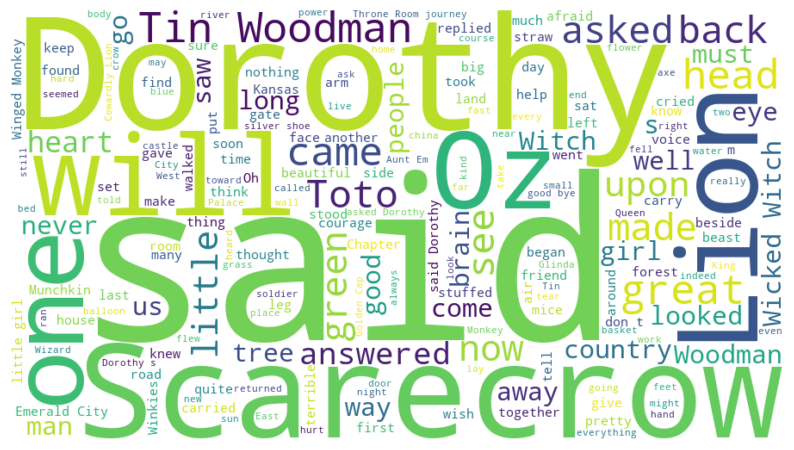

In [11]:
# make the cloud: the size of the image in pixels, a white background, and a fixed random_state
# (the layout uses random choices, and a fixed number makes them the same every time)
cloud = WordCloud(width=900, height=500, background_color="white", random_state=1).generate(text)

plt.figure(figsize=(10, 6))                  # the size of the plot, in inches
plt.imshow(cloud, interpolation="bilinear")  # draw the cloud's image (bilinear smooths it)
plt.axis("off")                              # hide the plot's axes
plt.show()

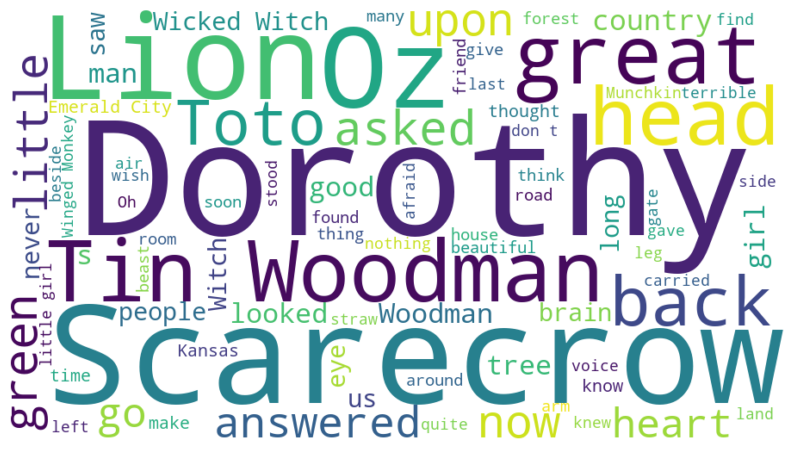

In [12]:
# STOPWORDS is a set, and | joins two sets together: the built-in stop words, plus a set of our own.
# Look at the first cloud, and add the words that are common but don't tell us much about this book
my_stopwords = STOPWORDS | {
    "one", "came", "first", "away", "together", "come", "went", "even", "really", "don't", "much", "tell", "sat", "big",
    "ask", "ran", "way", "new", "look", "said", "will", "see", "must", "help", "made", "chapter", "well", "took", "walked", 
    "replied", "day", "put", # headings and captions in the book, not part of its text
}

cloud = WordCloud(
    width=900,
    height=500,
    background_color="white",
    stopwords=my_stopwords,      # the words to leave out
    colormap="viridis",          # the color palette: try "plasma", "Set2", "Blues"
    max_words=80,                # only draw the 80 most common words
    random_state=1,
).generate(text)

plt.figure(figsize=(10, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

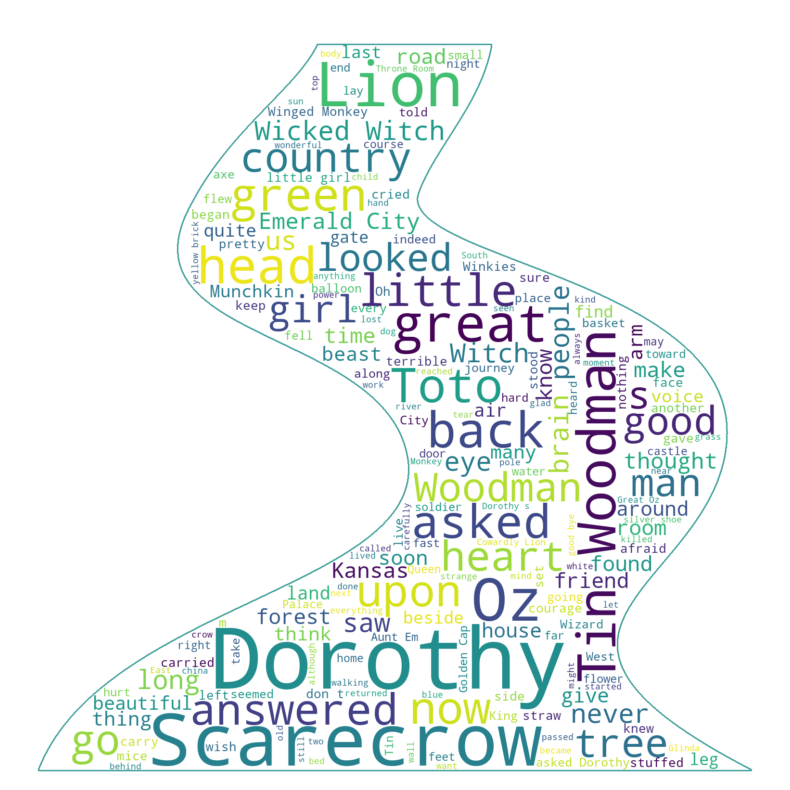

In [15]:
# Change the shape of the wordcloud -- use a "mask", or a shape, that I downloaded. I have chosen a winding road 
# to represent the Yellow Brick Road. 

img = Image.open("winding-road-mask.png").convert("RGBA")
white = Image.new("RGBA", img.size, "white")
road_mask = np.array(Image.alpha_composite(white, img).convert("RGB"))

# make the cloud in the shape of the road: words go only on the black parts
cloud = WordCloud(
    background_color="white",
    stopwords=my_stopwords,      # the same stop words as before
    colormap="viridis",
    max_words=200,               
    mask=road_mask,              # the shape of the cloud
    contour_width=2,             # optional: an outline around the road
    contour_color="#43a19c",
    random_state=1,
).generate(text)

plt.figure(figsize=(10, 10))     # square, to match the mask
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [16]:
# save the most recent cloud as a PNG image, in this folder
cloud.to_file("oz_cloud.png")